# CodeAlpha — Black Friday: Exploratory Data Analysis & Data Visualization

**Project type:** Data Analytics Internship — Task 2 (EDA) and Task 3 (Data Visualization)  
**Dataset:** Black Friday transaction data (`Black Friday Data.csv`)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy

## Project objective

Explore transaction-level Black Friday purchase data, assess data quality, describe customer and product-category patterns, compare purchase behaviour across segments, test one statistical hypothesis, and communicate findings through clear visualizations.

## Important interpretation rules

- Each row is a transaction record. Transaction counts are not the same as unique customer counts.
- `Purchase` is the recorded purchase amount. The dataset does not specify a currency, so this project does not attach a currency symbol.
- `Occupation`, `Marital_Status`, and product-category fields are codes/categories, not necessarily continuous measurements. Do not infer numerical distance or ranking from these codes.
- `Product_Category_2` and `Product_Category_3` contain missing values. We inspect them but do not fill them blindly.
- There is no date/time field, quantity field, unit-price field, or profit field. Therefore this dataset cannot support monthly trends, units sold, margin, or profitability analysis.

## 1. Import libraries and load the data

We use Pandas for tabular analysis, NumPy for numerical operations, Matplotlib and Seaborn for charts, and SciPy for a statistical test.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

# Find the project root whether Jupyter starts in the project folder or notebooks folder.
cwd = Path.cwd()
if (cwd / "data" / "Black Friday Data.csv").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "Black Friday Data.csv").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find data/Black Friday Data.csv. Open this notebook from the project folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "Black Friday Data.csv"
CHART_DIR = PROJECT_ROOT / "charts"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
CHART_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

# Consistent chart styling helper.
def save_chart(filename):
    plt.tight_layout()
    plt.savefig(CHART_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")

Dataset loaded successfully.


## 2. Understand the dataset structure

Before changing anything, inspect the first records, shape, column names, data types, and non-null counts.

In [2]:
display(df.head())
print("Dataset shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


Dataset shape (rows, columns): (550068, 12)

Column names:
['User_ID', 'Product_ID', 'Gender', 'Age', 'Occupation', 'City_Category', 'Stay_In_Current_City_Years', 'Marital_Status', 'Product_Category_1', 'Product_Category_2', 'Product_Category_3', 'Purchase']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  object 
 2   Gender                      550068 non-null  object 
 3   Age                         550068 non-null  object 
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  object 
 6   Stay_In_Current_City_Years  550068 non-null  object 
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1     

In [3]:
# Statistical summary for numeric fields.
display(df.describe().T)

# Number of distinct values in every column.
display(df.nunique().sort_values(ascending=False).rename("unique_values").to_frame())

,count,mean,std,min,25%,50%,75%,max
User_ID,550068.0,1.003029e+06,1727.591586,1000001.0,1001516.0,1003077.0,1004478.0,1006040.0
Occupation,550068.0,8.076707e+00,6.522660,0.0,2.0,7.0,14.0,20.0
Marital_Status,550068.0,4.096530e-01,0.491770,0.0,0.0,0.0,1.0,1.0
Product_Category_1,550068.0,5.404270e+00,3.936211,1.0,1.0,5.0,8.0,20.0
Product_Category_2,376430.0,9.842329e+00,5.086590,2.0,5.0,9.0,15.0,18.0
Product_Category_3,166821.0,1.266824e+01,4.125338,3.0,9.0,14.0,16.0,18.0
Purchase,550068.0,9.263969e+03,5023.065394,12.0,5823.0,8047.0,12054.0,23961.0


,unique_values
Purchase,18105
User_ID,5891
Product_ID,3631
Occupation,21
Product_Category_1,20
Product_Category_2,17
Product_Category_3,15
Age,7
Stay_In_Current_City_Years,5
City_Category,3


### Initial structural observations

- Rows represent purchase transactions, not one row per customer.
- `User_ID` and `Product_ID` are identifiers. Their numeric/string ordering has no quantitative meaning.
- `Age` and `Stay_In_Current_City_Years` are stored as text categories, which is appropriate for grouped analysis.
- Category columns are codes. They should be treated as categorical variables when comparing groups.

## 3. Data quality assessment

We quantify missing values, exact duplicate rows, and basic category/range checks. This section diagnoses issues; it does not automatically delete or impute records.

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)
print("Exact duplicate rows:", df.duplicated().sum())

,missing_count,missing_percent,dtype,unique_values
Product_Category_3,383247,69.67,float64,15
Product_Category_2,173638,31.57,float64,17
User_ID,0,0.00,int64,5891
Product_ID,0,0.00,object,3631
Age,0,0.00,object,7
Gender,0,0.00,object,2
Occupation,0,0.00,int64,21
City_Category,0,0.00,object,3
Marital_Status,0,0.00,int64,2
Stay_In_Current_City_Years,0,0.00,object,5


Exact duplicate rows: 0


In [5]:
# Check key categorical values and basic numeric ranges.
for col in ["Gender", "Age", "City_Category", "Stay_In_Current_City_Years", "Marital_Status"]:
    print(f"\n{col} values:")
    print(sorted(df[col].dropna().unique().tolist(), key=str))

print("\nPurchase minimum:", df["Purchase"].min())
print("Purchase maximum:", df["Purchase"].max())
print("Purchase values <= 0:", (df["Purchase"] <= 0).sum())


Gender values:
['F', 'M']

Age values:
['0-17', '18-25', '26-35', '36-45', '46-50', '51-55', '55+']

City_Category values:
['A', 'B', 'C']

Stay_In_Current_City_Years values:
['0', '1', '2', '3', '4+']

Marital_Status values:
[0, 1]

Purchase minimum: 12
Purchase maximum: 23961
Purchase values <= 0: 0


### Data quality decision

`Product_Category_2` is missing in about 31.57% of records and `Product_Category_3` in about 69.67%. These may represent unavailable/unused secondary category assignments rather than ordinary numeric measurement gaps. We retain the original values and do not use mean/median imputation. There are no exact duplicate rows in this file.

# Part A — Exploratory Data Analysis

## 4. Univariate analysis: one variable at a time

Univariate analysis describes the distribution of a single field. For categorical fields we inspect counts and percentages; for `Purchase` we inspect summary statistics and its distribution.

### 4.1 Gender distribution

`value_counts()` reports transaction frequency by gender. `normalize=True` converts the frequencies into proportions.

,transactions,transaction_share_percent
Gender,,
M,414259,75.31
F,135809,24.69


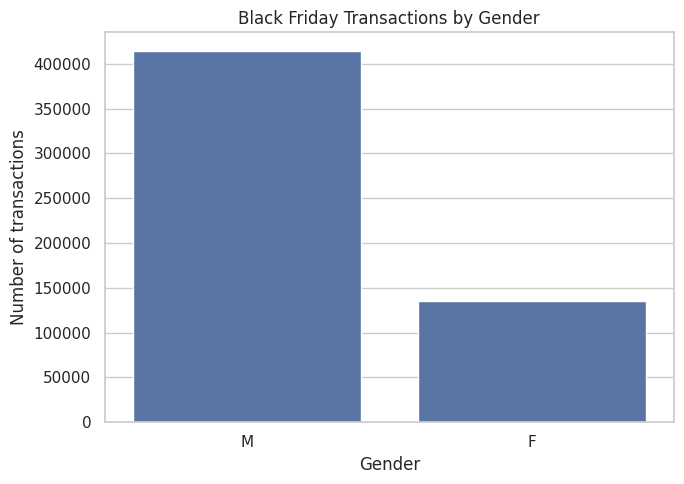

In [6]:
gender_counts = df["Gender"].value_counts()
gender_share = (df["Gender"].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"transactions": gender_counts, "transaction_share_percent": gender_share}))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Gender", order=gender_counts.index, color="#4C72B0")
plt.title("Black Friday Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of transactions")
save_chart("01_gender_distribution.png")

### 4.2 Age-group distribution

Age is already grouped into bands. We explicitly define the natural order so the chart is not sorted alphabetically.

,transactions,transaction_share_percent
Age,,
0-17,15102,2.75
18-25,99660,18.12
26-35,219587,39.92
36-45,110013,20.00
46-50,45701,8.31
51-55,38501,7.00
55+,21504,3.91


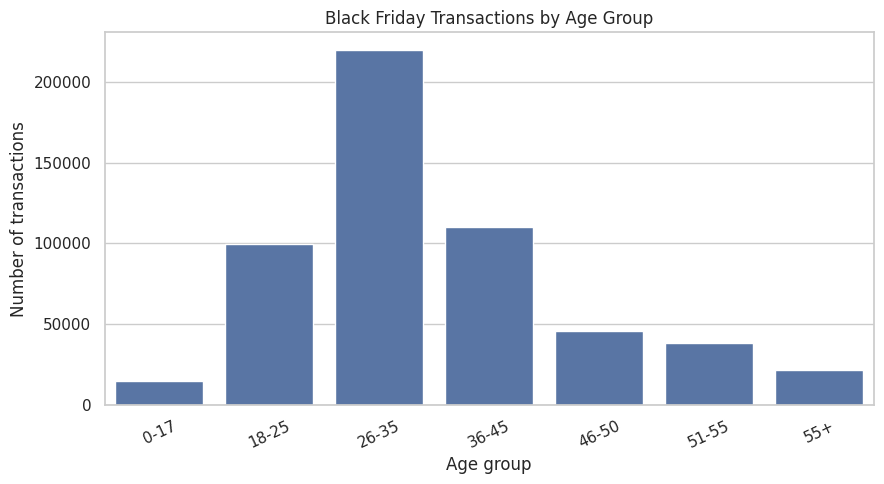

In [7]:
age_order = ["0-17", "18-25", "26-35", "36-45", "46-50", "51-55", "55+"]
age_counts = df["Age"].value_counts().reindex(age_order)
age_share = (df["Age"].value_counts(normalize=True).reindex(age_order) * 100).round(2)
display(pd.DataFrame({"transactions": age_counts, "transaction_share_percent": age_share}))

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Age", order=age_order, color="#4C72B0")
plt.title("Black Friday Transactions by Age Group")
plt.xlabel("Age group")
plt.ylabel("Number of transactions")
plt.xticks(rotation=25)
save_chart("02_age_group_distribution.png")

### 4.3 City-category distribution

,transactions,transaction_share_percent
City_Category,,
A,147720,26.85
B,231173,42.03
C,171175,31.12


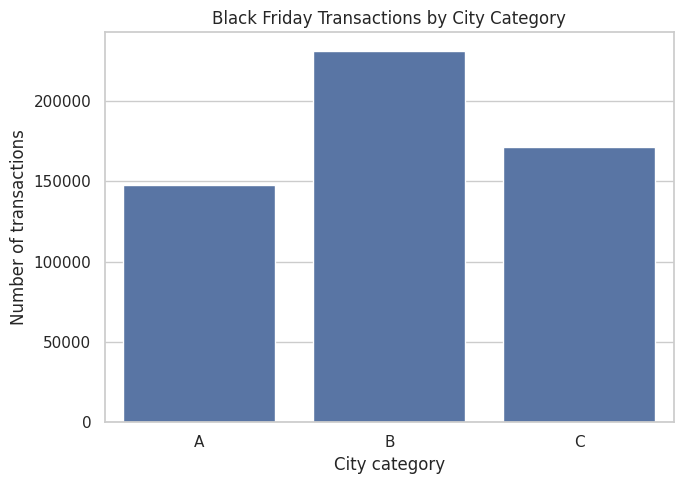

In [8]:
city_counts = df["City_Category"].value_counts().reindex(["A", "B", "C"])
city_share = (df["City_Category"].value_counts(normalize=True).reindex(["A", "B", "C"]) * 100).round(2)
display(pd.DataFrame({"transactions": city_counts, "transaction_share_percent": city_share}))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="City_Category", order=["A", "B", "C"], color="#4C72B0")
plt.title("Black Friday Transactions by City Category")
plt.xlabel("City category")
plt.ylabel("Number of transactions")
save_chart("03_city_category_distribution.png")

### 4.4 Product Category 1 distribution

We first look at which category codes appear most often. This is transaction volume, not total purchase amount.

,transactions
Product_Category_1,
5,150933
1,140378
8,113925
11,24287
2,23864
6,20466
3,20213
4,11753
16,9828


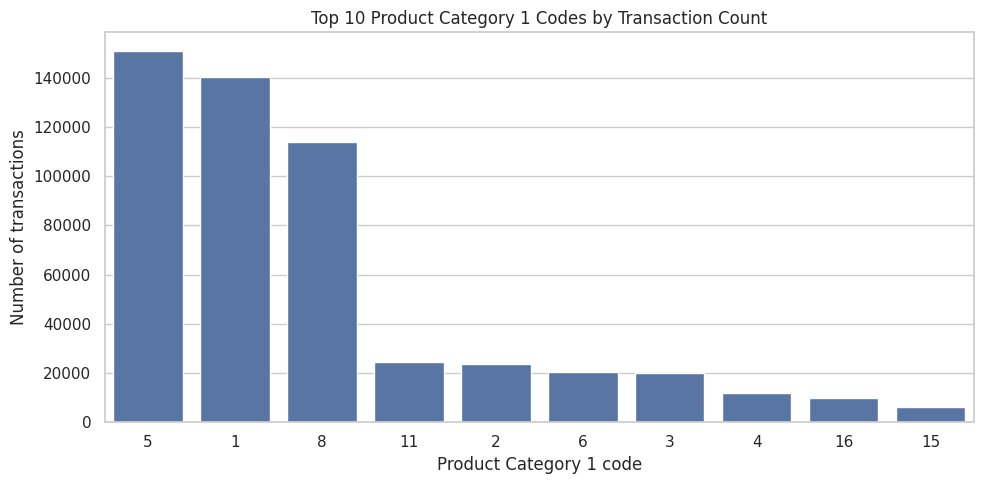

In [9]:
category1_counts = df["Product_Category_1"].value_counts().sort_values(ascending=False)
display(category1_counts.rename_axis("Product_Category_1").rename("transactions").to_frame().head(10))

plt.figure(figsize=(10, 5))
sns.barplot(x=category1_counts.head(10).index.astype(str), y=category1_counts.head(10).values, color="#4C72B0")
plt.title("Top 10 Product Category 1 Codes by Transaction Count")
plt.xlabel("Product Category 1 code")
plt.ylabel("Number of transactions")
save_chart("04_top_category1_by_transactions.png")

### 4.5 Purchase distribution (numerical variable)

For `Purchase`, inspect center, spread, quantiles, and shape. A histogram shows the distribution; a box plot highlights spread and potential extreme observations.

,Purchase
count,550068.000000
mean,9263.968713
std,5023.065394
min,12.000000
25%,5823.000000
50%,8047.000000
75%,12054.000000
max,23961.000000


Median: 8047.0
Skewness: 0.6


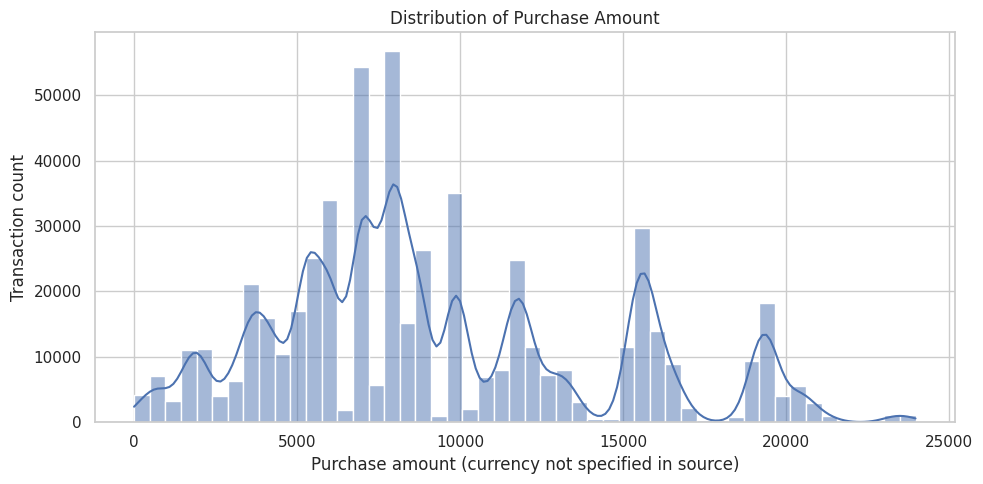

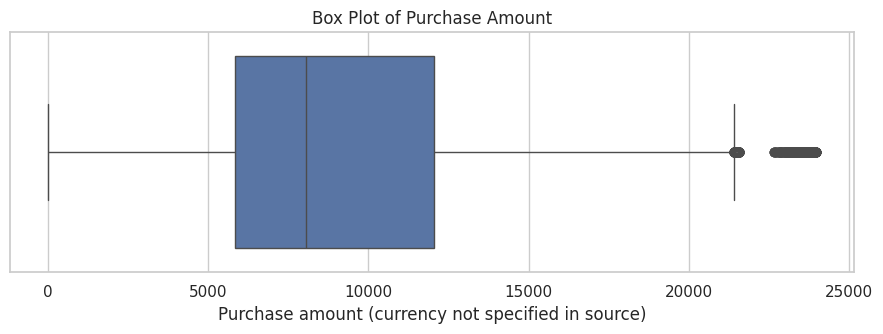

In [10]:
purchase_summary = df["Purchase"].describe().to_frame(name="Purchase")
display(purchase_summary)
print("Median:", df["Purchase"].median())
print("Skewness:", round(df["Purchase"].skew(), 3))

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Purchase", bins=50, kde=True, color="#4C72B0")
plt.title("Distribution of Purchase Amount")
plt.xlabel("Purchase amount (currency not specified in source)")
plt.ylabel("Transaction count")
save_chart("05_purchase_distribution.png")

plt.figure(figsize=(9, 3.5))
sns.boxplot(data=df, x="Purchase", color="#4C72B0")
plt.title("Box Plot of Purchase Amount")
plt.xlabel("Purchase amount (currency not specified in source)")
save_chart("06_purchase_boxplot.png")

### Univariate observations

- Male records make up approximately 75.31% of transactions; female records make up 24.69%.
- The 26–35 age band contributes approximately 39.92% of transactions, the largest age segment.
- City category B contributes approximately 42.03% of transactions, the largest city segment by transaction count.
- Product Category 1 code 5 is the most frequent category by transaction count.
- Mean `Purchase` is greater than the median. We investigate its distribution and potential outliers rather than assuming every high value is an error.

## 5. Bivariate analysis: compare two variables

Here we compare purchase outcomes across customer or city segments. Each summary includes transaction count, unique customers, total purchase, average purchase, and median purchase. This prevents us from confusing high transaction volume with high average transaction value.

,transactions,unique_customers,total_purchase,average_purchase,median_purchase
Gender,,,,,
M,414259,4225,3909580100,9437.526040,8098.0
F,135809,1666,1186232642,8734.565765,7914.0


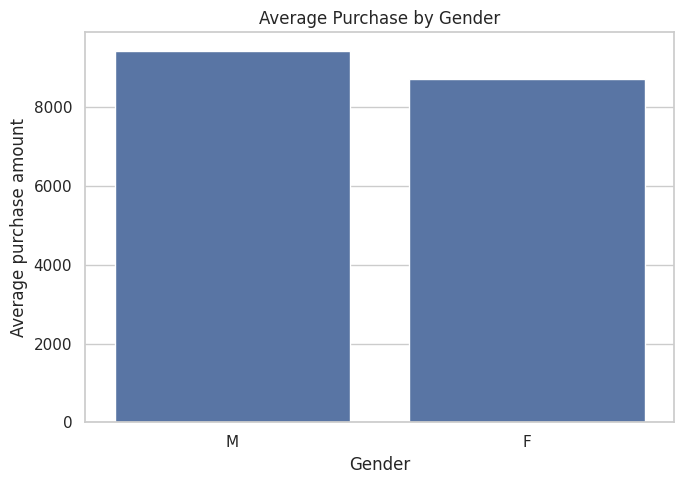

In [11]:
def segment_summary(data, group_col):
    return (
        data.groupby(group_col, dropna=False)
        .agg(
            transactions=("Purchase", "size"),
            unique_customers=("User_ID", "nunique"),
            total_purchase=("Purchase", "sum"),
            average_purchase=("Purchase", "mean"),
            median_purchase=("Purchase", "median")
        )
        .sort_values("total_purchase", ascending=False)
    )

gender_summary = segment_summary(df, "Gender")
display(gender_summary)

plt.figure(figsize=(7, 5))
sns.barplot(data=gender_summary.reset_index(), x="Gender", y="average_purchase", color="#4C72B0")
plt.title("Average Purchase by Gender")
plt.xlabel("Gender")
plt.ylabel("Average purchase amount")
save_chart("07_average_purchase_by_gender.png")

### 5.1 Purchase behaviour by age group

,transactions,unique_customers,total_purchase,average_purchase,median_purchase
Age,,,,,
0-17,15102,218,134913183,8933.464640,7986.0
18-25,99660,1069,913848675,9169.663606,8027.0
26-35,219587,2053,2031770578,9252.690633,8030.0
36-45,110013,1167,1026569884,9331.350695,8061.0
46-50,45701,531,420843403,9208.625697,8036.0
51-55,38501,481,367099644,9534.808031,8130.0
55+,21504,372,200767375,9336.280459,8105.5


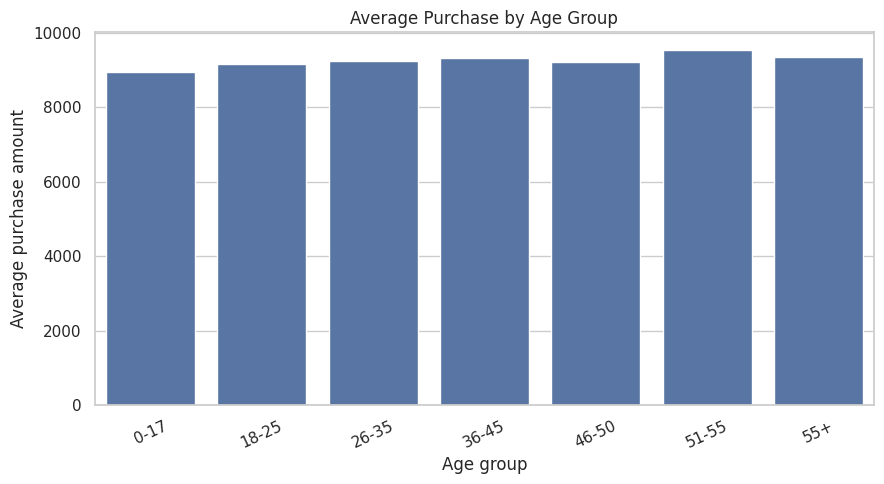

In [12]:
age_summary = segment_summary(df, "Age").reindex(age_order)
display(age_summary)

plt.figure(figsize=(9, 5))
sns.barplot(x=age_summary.index, y=age_summary["average_purchase"].values, color="#4C72B0")
plt.title("Average Purchase by Age Group")
plt.xlabel("Age group")
plt.ylabel("Average purchase amount")
plt.xticks(rotation=25)
save_chart("08_average_purchase_by_age.png")

### 5.2 Purchase behaviour by city category

,transactions,unique_customers,total_purchase,average_purchase,median_purchase
City_Category,,,,,
A,147720,1045,1316471661,8911.939216,7931.0
B,231173,1707,2115533605,9151.300563,8005.0
C,171175,3139,1663807476,9719.920993,8585.0


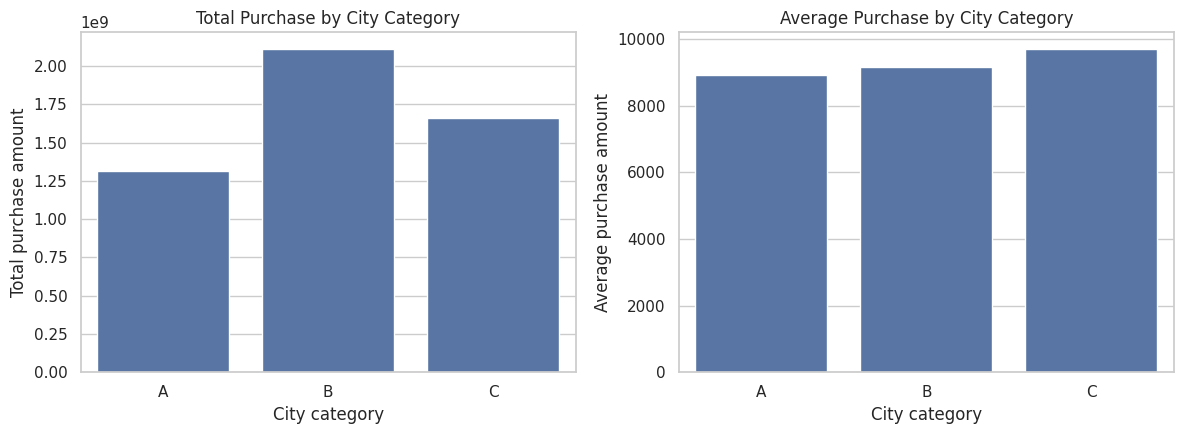

In [13]:
city_summary = segment_summary(df, "City_Category").reindex(["A", "B", "C"])
display(city_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=city_summary.index, y=city_summary["total_purchase"].values, ax=axes[0], color="#4C72B0")
axes[0].set_title("Total Purchase by City Category")
axes[0].set_xlabel("City category")
axes[0].set_ylabel("Total purchase amount")
sns.barplot(x=city_summary.index, y=city_summary["average_purchase"].values, ax=axes[1], color="#4C72B0")
axes[1].set_title("Average Purchase by City Category")
axes[1].set_xlabel("City category")
axes[1].set_ylabel("Average purchase amount")
plt.tight_layout()
plt.savefig(CHART_DIR / "09_city_category_performance.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

### 5.3 Marital-status comparison

The source encodes marital status as 0 and 1. We preserve those labels because the file does not provide a separate codebook in the CSV itself.

In [14]:
marital_summary = segment_summary(df, "Marital_Status").sort_index()
display(marital_summary)

,transactions,unique_customers,total_purchase,average_purchase,median_purchase
Marital_Status,,,,,
0,324731,3417,3008927447,9265.907619,8044.0
1,225337,2474,2086885295,9261.174574,8051.0


### 5.4 Purchase behaviour by city tenure

The tenure field is categorical (`0`, `1`, `2`, `3`, `4+`). Compare both transaction volume and average purchase; do not convert `4+` into an exact number.

,transactions,unique_customers,total_purchase,average_purchase,median_purchase
Stay_In_Current_City_Years,,,,,
0,74398,772,682979229,9180.075123,8025.0
1,193821,2086,1792872533,9250.145923,8041.0
2,101838,1145,949173931,9320.429810,8072.0
3,95285,979,884902659,9286.904119,8047.0
4+,84726,909,785884390,9275.598872,8052.0


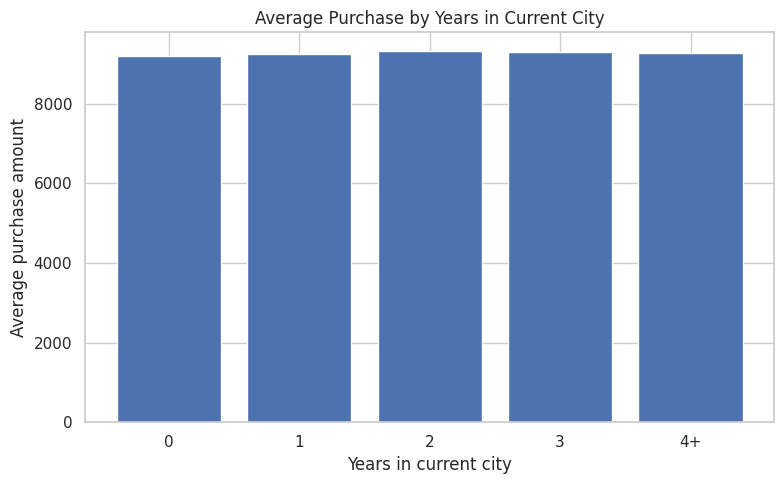

In [15]:
tenure_order = ["0", "1", "2", "3", "4+"]
tenure_summary = segment_summary(df, "Stay_In_Current_City_Years").reindex(tenure_order)
display(tenure_summary)

plt.figure(figsize=(8, 5))
plt.bar(tenure_summary.index, tenure_summary["average_purchase"])
plt.title("Average Purchase by Years in Current City")
plt.xlabel("Years in current city")
plt.ylabel("Average purchase amount")
save_chart("13_average_purchase_by_city_tenure.png")


### 5.5 Occupation-code analysis

Occupation is represented by codes 0–20. Since no codebook is supplied, we compare codes without assigning job titles to them.

,transactions,unique_customers,total_purchase,average_purchase,median_purchase
Occupation,,,,,
4,72308,740,666244484,9213.980251,8043.0
0,69638,688,635406958,9124.428588,8001.0
7,59133,669,557371587,9425.728223,8069.0
1,47426,517,424614144,8953.193270,7966.0
17,40043,491,393281453,9821.478236,8635.0
20,33562,273,296570442,8836.494905,7903.5
12,31179,376,305449446,9796.640239,8569.0
14,27309,294,259454692,9500.702772,8122.0
2,26588,256,238028583,8952.481683,7952.0


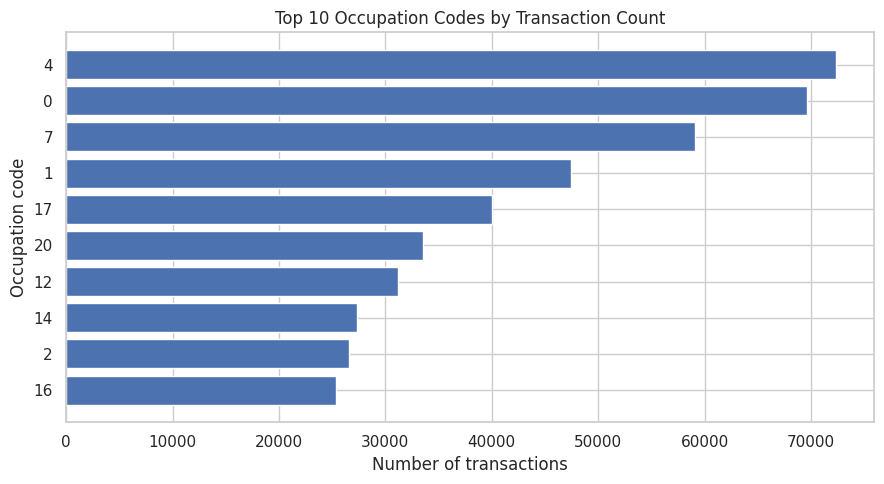

In [16]:
occupation_summary = segment_summary(df, "Occupation")
display(occupation_summary.sort_values("transactions", ascending=False).head(10))

top_occupation_volume = occupation_summary.sort_values("transactions", ascending=False).head(10).sort_values("transactions")
plt.figure(figsize=(9, 5))
plt.barh(top_occupation_volume.index.astype(str), top_occupation_volume["transactions"])
plt.title("Top 10 Occupation Codes by Transaction Count")
plt.xlabel("Number of transactions")
plt.ylabel("Occupation code")
save_chart("14_top_occupation_codes_by_transactions.png")


### 5.6 Combined age and gender view

A pivot table lets us compare mean purchase for two categorical dimensions together. This is a grouped comparison, not a correlation matrix.

Gender,F,M
Age,,
0-17,8338.771985,9235.173670
18-25,8343.180201,9440.942971
26-35,8728.251754,9410.337578
36-45,8959.844056,9453.193643
46-50,8842.098947,9357.471509
51-55,9042.449666,9705.094802
55+,9007.036199,9438.195603


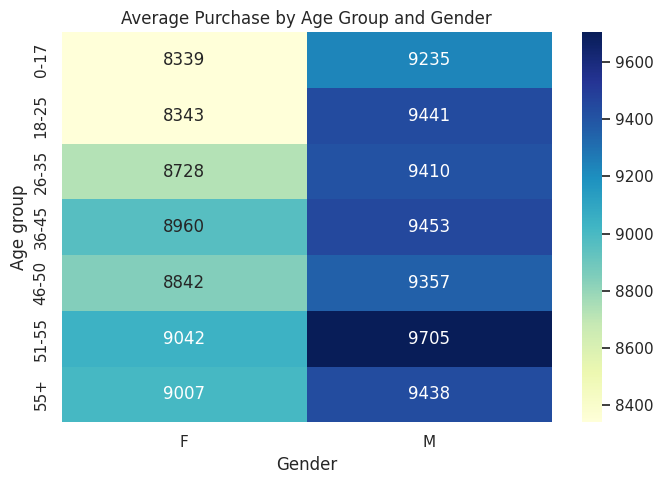

In [17]:
age_gender_average = df.pivot_table(
    values="Purchase", index="Age", columns="Gender", aggfunc="mean"
).reindex(age_order)
display(age_gender_average)

plt.figure(figsize=(7, 5))
sns.heatmap(age_gender_average, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Average Purchase by Age Group and Gender")
plt.xlabel("Gender")
plt.ylabel("Age group")
save_chart("15_average_purchase_age_gender_heatmap.png")


## 6. Product-category analysis

Compare transaction volume and total purchase amount separately. A category with many transactions is not necessarily the category with the highest total purchase amount.

,transactions,unique_customers,total_purchase,average_purchase,median_purchase
Product_Category_1,,,,,
5,150933,5751,941835229,6240.088178,6912.0
1,140378,5767,1910013754,13606.218596,15245.0
8,113925,5659,854318799,7498.958078,7905.0
11,24287,3583,113791115,4685.268456,4611.0
2,23864,4296,268516186,11251.935384,12728.5
6,20466,4085,324150302,15838.478550,16312.0
3,20213,3838,204084713,10096.705734,10742.0
4,11753,3361,27380488,2329.659491,2175.0
16,9828,3130,145120612,14766.037037,16292.5


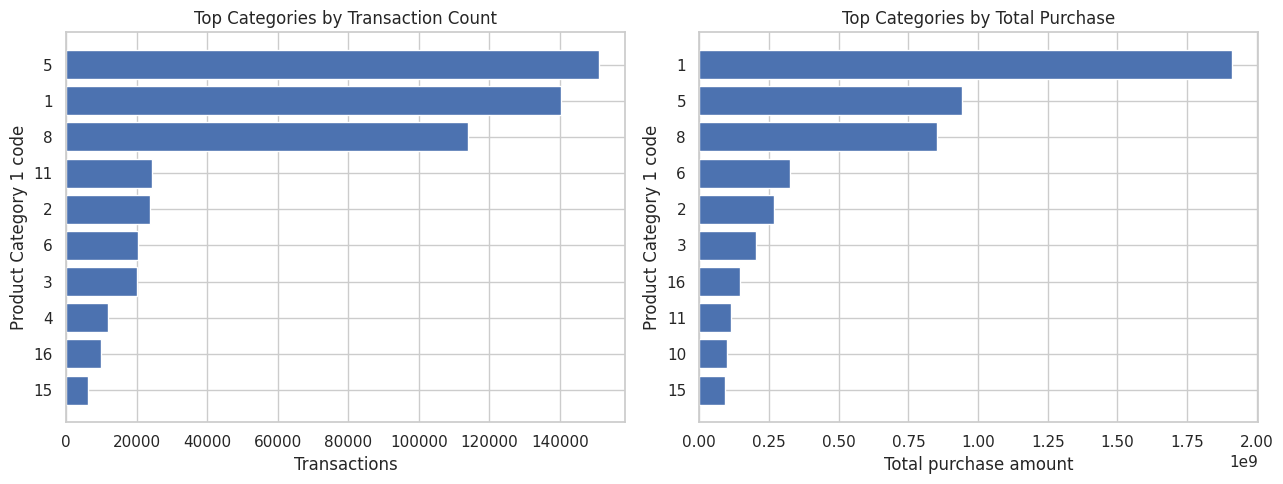

In [18]:
category1_summary = segment_summary(df, "Product_Category_1").sort_values("transactions", ascending=False)
display(category1_summary.head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_volume = category1_summary.head(10).sort_values("transactions", ascending=True)
axes[0].barh(top_volume.index.astype(str), top_volume["transactions"])
axes[0].set_title("Top Categories by Transaction Count")
axes[0].set_xlabel("Transactions")
axes[0].set_ylabel("Product Category 1 code")
top_total = category1_summary.sort_values("total_purchase", ascending=False).head(10).sort_values("total_purchase", ascending=True)
axes[1].barh(top_total.index.astype(str), top_total["total_purchase"])
axes[1].set_title("Top Categories by Total Purchase")
axes[1].set_xlabel("Total purchase amount")
axes[1].set_ylabel("Product Category 1 code")
plt.tight_layout()
plt.savefig(CHART_DIR / "10_category_volume_vs_total_purchase.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

## 7. Product-level analysis

`Product_ID` is an identifier. We aggregate by product to identify products with the highest transaction count and highest total purchase amount. These are different questions from average purchase value.

Top 10 products by transaction count:


,transactions,total_purchase,average_purchase
Product_ID,,,
P00265242,1880,14165515,7534.848404
P00025442,1615,27995166,17334.468111
P00110742,1612,26722309,16577.114764
P00112142,1562,24216006,15503.204866
P00057642,1470,23102780,15716.176871
P00184942,1440,24334887,16899.227083
P00046742,1438,21152882,14709.931850
P00058042,1422,12250634,8615.073136
P00059442,1406,24338343,17310.343528


Top 10 products by total purchase:


,transactions,total_purchase,average_purchase
Product_ID,,,
P00025442,1615,27995166,17334.468111
P00110742,1612,26722309,16577.114764
P00255842,1383,25168963,18198.816341
P00059442,1406,24338343,17310.343528
P00184942,1440,24334887,16899.227083
P00112142,1562,24216006,15503.204866
P00110942,1360,23639564,17382.032353
P00237542,1394,23425576,16804.573888
P00057642,1470,23102780,15716.176871


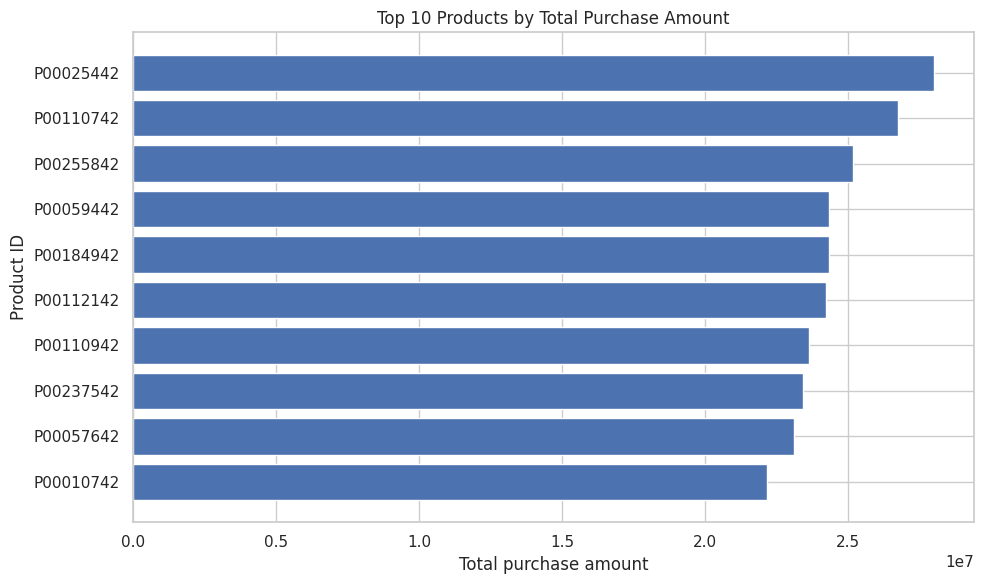

In [19]:
product_summary = (
    df.groupby("Product_ID")
    .agg(
        transactions=("Purchase", "size"),
        total_purchase=("Purchase", "sum"),
        average_purchase=("Purchase", "mean")
    )
)

top_products_by_transactions = product_summary.sort_values("transactions", ascending=False).head(10)
top_products_by_total = product_summary.sort_values("total_purchase", ascending=False).head(10)
print("Top 10 products by transaction count:")
display(top_products_by_transactions)
print("Top 10 products by total purchase:")
display(top_products_by_total)

plot_data = top_products_by_total.sort_values("total_purchase", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(plot_data.index, plot_data["total_purchase"])
plt.title("Top 10 Products by Total Purchase Amount")
plt.xlabel("Total purchase amount")
plt.ylabel("Product ID")
save_chart("11_top_products_by_total_purchase.png")

## 8. Customer-level analysis

The raw file has multiple transaction rows per customer. We therefore create a separate customer-level table. `total_spend` is the sum of recorded purchase amounts per User_ID; `transactions` is the number of rows per User_ID.

,count,mean,std,min,25%,50%,75%,max
transactions,5891.0,93.374300,107.190049,6.000000,26.000000,54.000000,1.170000e+02,1.026000e+03
total_spend,5891.0,865016.591750,943644.539683,46681.000000,237678.000000,521213.000000,1.119250e+06,1.053691e+07
average_transaction,5891.0,9568.839914,1890.087105,2318.733333,8287.212366,9386.208333,1.065463e+04,1.857789e+04


Unique customers: 5891


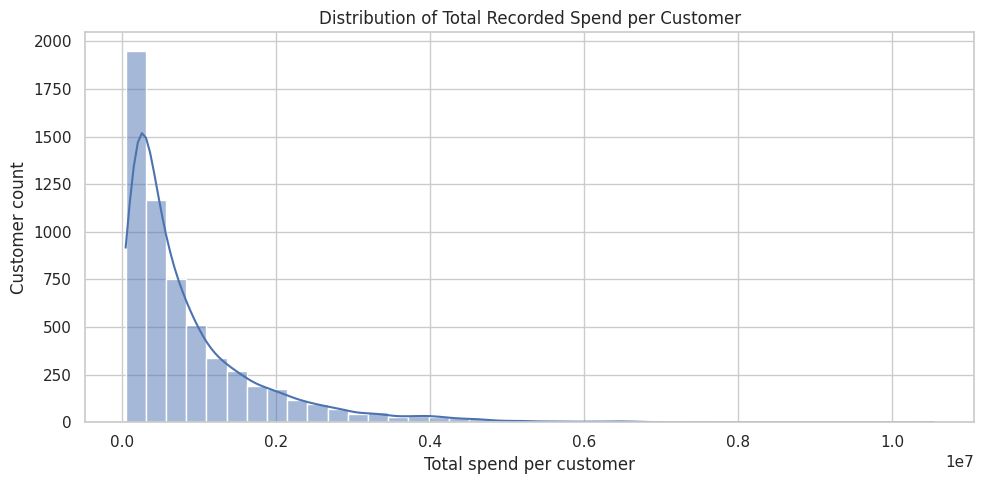

In [20]:
customer_summary = (
    df.groupby("User_ID")
    .agg(
        transactions=("Purchase", "size"),
        total_spend=("Purchase", "sum"),
        average_transaction=("Purchase", "mean")
    )
)

display(customer_summary.describe().T)
print("Unique customers:", customer_summary.shape[0])

plt.figure(figsize=(10, 5))
sns.histplot(data=customer_summary, x="total_spend", bins=40, kde=True, color="#4C72B0")
plt.title("Distribution of Total Recorded Spend per Customer")
plt.xlabel("Total spend per customer")
plt.ylabel("Customer count")
save_chart("12_customer_total_spend_distribution.png")

## 9. Outlier investigation for Purchase

We use the IQR rule as a screening method:

- IQR = Q3 − Q1
- Lower fence = Q1 − 1.5 × IQR
- Upper fence = Q3 + 1.5 × IQR

A value outside the fences is a *potential statistical outlier*, not automatically a data error. We keep all rows unless business validation confirms an error.

In [21]:
q1 = df["Purchase"].quantile(0.25)
q3 = df["Purchase"].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

lower_outliers = int((df["Purchase"] < lower_fence).sum())
upper_outliers = int((df["Purchase"] > upper_fence).sum())
outlier_count = lower_outliers + upper_outliers
outlier_percent = outlier_count / len(df) * 100

print(f"Q1: {q1:,.2f}")
print(f"Q3: {q3:,.2f}")
print(f"IQR: {iqr:,.2f}")
print(f"Lower fence: {lower_fence:,.2f}")
print(f"Upper fence: {upper_fence:,.2f}")
print(f"Lower outliers: {lower_outliers:,}")
print(f"Upper outliers: {upper_outliers:,}")
print(f"Total potential outliers: {outlier_count:,} ({outlier_percent:.2f}%)")

Q1: 5,823.00
Q3: 12,054.00
IQR: 6,231.00
Lower fence: -3,523.50
Upper fence: 21,400.50
Lower outliers: 0
Upper outliers: 2,677
Total potential outliers: 2,677 (0.49%)


## 10. Hypothesis test: average transaction purchase per customer by gender

**Question:** Do male and female customers have different average transaction purchase values in this dataset?

- Null hypothesis (H0): the mean of customers' average transaction purchase is equal between the two groups.
- Alternative hypothesis (H1): the two group means are different.
- Unit of analysis: one row per customer, not one row per transaction. This avoids treating a customer's repeated transactions as independent observations.
- Test: Welch's independent two-sample t-test, which does not assume equal group variances.
- Significance level: 0.05.

This is an observational comparison; it does not establish that gender causes a difference. A large sample can make small differences statistically significant, so consider the magnitude as well as the p-value.

In [22]:
# Build one row per customer. First confirm that each user has one consistent gender value.
customer_profile = (
    df.groupby("User_ID")
    .agg(
        Gender=("Gender", "first"),
        gender_values=("Gender", "nunique"),
        transactions=("Purchase", "size"),
        average_transaction=("Purchase", "mean"),
        total_spend=("Purchase", "sum")
    )
)
print("Customers with inconsistent gender labels:", (customer_profile["gender_values"] != 1).sum())

customer_avg_m = customer_profile.loc[customer_profile["Gender"] == "M", "average_transaction"]
customer_avg_f = customer_profile.loc[customer_profile["Gender"] == "F", "average_transaction"]

welch_result = stats.ttest_ind(customer_avg_m, customer_avg_f, equal_var=False)
mean_m = customer_avg_m.mean()
mean_f = customer_avg_f.mean()
mean_difference = mean_m - mean_f
alpha = 0.05

print(f"Male customers: {len(customer_avg_m):,}")
print(f"Female customers: {len(customer_avg_f):,}")
print(f"Mean customer-level average transaction (M): {mean_m:,.2f}")
print(f"Mean customer-level average transaction (F): {mean_f:,.2f}")
print(f"Mean difference (M - F): {mean_difference:,.2f}")
print(f"Welch t-statistic: {welch_result.statistic:,.3f}")
print("p-value: < 0.001" if welch_result.pvalue < 0.001 else f"p-value: {welch_result.pvalue:.6f}")

if welch_result.pvalue < alpha:
    print("Decision: Reject H0 at the 5% significance level.")
else:
    print("Decision: Fail to reject H0 at the 5% significance level.")

Customers with inconsistent gender labels: 0
Male customers: 4,225
Female customers: 1,666
Mean customer-level average transaction (M): 9,806.87
Mean customer-level average transaction (F): 8,965.20
Mean difference (M - F): 841.67
Welch t-statistic: 16.486
p-value: < 0.001
Decision: Reject H0 at the 5% significance level.


## 11. Key findings and business interpretation

Use the computed tables above to support every statement. Keep these distinctions clear:

1. **Transaction mix:** male records form the majority of transactions in this file. This does not by itself tell us the number of unique male customers or average purchase value.
2. **Age segment:** 26–35 is the largest segment by transaction volume. The highest-volume group is not automatically the highest-average-purchase group.
3. **City comparison:** City B has the highest total transaction volume and total recorded purchase amount; City C has the highest average purchase amount per transaction.
4. **Product category:** Product Category 1 code 5 has the most transactions, while code 1 has the highest total recorded purchase amount.
5. **Purchase spread:** the mean exceeds the median and the distribution is positively skewed. A small number of high values influence the upper tail.
6. **Potential outliers:** IQR screening flags 2,677 purchase values (about 0.49%). These should be investigated, not deleted automatically.
7. **Missing category metadata:** Category 2 and Category 3 have substantial missingness. The missingness treatment needs business context.
8. **Hypothesis test:** the observed mean purchase differs between the M and F groups at the 5% significance level. The difference is descriptive/statistical, not causal.

## 12. Limitations and next steps

- No date/time column: no daily, weekly, monthly, or seasonal trend can be calculated.
- No quantity or unit-price fields: units sold and unit pricing cannot be derived.
- No cost/profit/margin fields: profitability cannot be measured.
- Category and occupation values are codes; external code descriptions are not included in this CSV.
- The file is transaction-level and observational; results should not be interpreted as causal effects.
- `User_ID` is an identifier, not a numeric feature. It should not be used in correlation or statistical modelling as a continuous variable.

## 13. Export analysis tables

The following code saves key summary tables in the `outputs/` folder so they can be reused in a report or dashboard.

In [23]:
missing_summary.to_csv(OUTPUT_DIR / "missing_values_summary.csv")
gender_summary.to_csv(OUTPUT_DIR / "gender_purchase_summary.csv")
age_summary.to_csv(OUTPUT_DIR / "age_purchase_summary.csv")
city_summary.to_csv(OUTPUT_DIR / "city_purchase_summary.csv")
category1_summary.to_csv(OUTPUT_DIR / "product_category1_summary.csv")
product_summary.sort_values("total_purchase", ascending=False).to_csv(OUTPUT_DIR / "product_summary.csv")
customer_summary.to_csv(OUTPUT_DIR / "customer_level_summary.csv")
customer_profile.to_csv(OUTPUT_DIR / "customer_profile_for_testing.csv")

print("Analysis tables exported to:", OUTPUT_DIR)
print("Charts saved to:", CHART_DIR)

Analysis tables exported to: /mnt/data/CodeAlpha_Black_Friday_EDA_Visualization/outputs
Charts saved to: /mnt/data/CodeAlpha_Black_Friday_EDA_Visualization/charts


## 14. Final project checklist

- [x] Dataset loaded and understood
- [x] Data quality inspected
- [x] Univariate analysis completed
- [x] Bivariate and segment analysis completed
- [x] Product- and customer-level summaries created
- [x] Purchase outliers investigated using IQR
- [x] One statistical hypothesis tested
- [x] Visualizations saved as PNG files
- [x] Summary tables exported as CSV files
- [ ] Review charts and findings, then record a short project walkthrough for submission